# Sistemas dinámicos, cálculo de variaciones, control óptimo y programación dinámica
## Cuaderno de práctica (Google Colab)

**Ph.D. Miguel Flores · Seminario doctoral en Informática**

Este cuaderno acompaña la presentación en PDF *Sistemas_dinamicos_variaciones_control_PD.pdf*. Cada sección indica las
**diapositivas** que reproduce. El objetivo es que **compruebe con código cada número de la presentación** y que pueda
modificar los ejemplos.

**Cómo usarlo**
1. Ejecute las celdas en orden con *Mayús + Enter* (o *Entorno de ejecución → Ejecutar todas*).
2. Cada sección termina con una línea `✔ ...` cuando la comprobación es correcta.
3. Las celdas marcadas **Pruébelo** le invitan a cambiar un número y observar el efecto.
4. Al final hay **ejercicios** con espacios `TODO` y sus soluciones en la última sección.

Ejecute la primera celda de código para instalar las librerías necesarias en el entorno del cuaderno.

In [1]:
%pip install numpy scipy sympy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Importa NumPy para trabajar con vectores, matrices y funciones numéricas.
import numpy as np
# Importa SymPy para derivar, integrar y resolver ecuaciones de forma simbólica.
import sympy as sp
# Importa la interfaz de Matplotlib que dibuja las trayectorias y las funciones de coste.
import matplotlib.pyplot as plt
# Importa quad para integrales definidas y solve_ivp para ecuaciones diferenciales con condición inicial.
from scipy.integrate import quad, solve_ivp
# Importa un minimizador para vectores y otro para funciones de una sola variable.
from scipy.optimize import minimize, minimize_scalar
# Importa utilidades para enumerar combinaciones (itertools) y manejar colas de prioridad (heapq).
import itertools, heapq

# Define la paleta que permite distinguir estados, controles y soluciones en las gráficas.
AZUL, NARANJA, VERDE, ROJO, GRIS = "#2E6FB0", "#C8701E", "#2F7D54", "#B23A3A", "#8A94A0"
# Configura la resolución y activa una cuadrícula tenue para leer valores en los ejes.
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     # Oculta los bordes superior y derecho de las gráficas.
                     "axes.spines.top": False, "axes.spines.right": False})
# Define una función común para presentar los resultados de las comprobaciones.
def ok(msg):
    # Escribe el mensaje con una marca de verificación.
    print("✔", msg)

---
# Bloque 0 · Herramientas previas
## 0.1 Derivada como tasa de cambio (diapositiva 7)
La derivada es el límite de $\frac{x(t+h)-x(t)}{h}$ cuando $h\to0$. Con $x(t)=t^2$ en $t=3$ debe dar 6.

In [3]:
# Define la función cuadrática x(t) = t² que se utilizará para aproximar la pendiente.
x = lambda t: t**2
# Diap. 7. El cociente hacia adelante (x(3+h) − x(3))/h estima la pendiente en t = 3.
# Al reducir h, el cociente se acerca al límite que define la derivada.
for h in [0.1, 0.01, 0.001]:
    # Muestra el cociente incremental para cada h y redondea el resultado a cuatro decimales.
    print(f"h = {h:<6}  (x(3+h) - x(3))/h = {(x(3+h) - x(3))/h:.4f}")
# Declara t como variable simbólica para obtener la derivada exacta.
t = sp.symbols("t")
# La regla de la potencia da d(t²)/dt = 2t. Evaluada en t = 3, la pendiente es 6.
print("Derivada simbólica de t²:", sp.diff(t**2, t))
# Comprueba que con h = 10⁻⁶ el cociente difiere de la pendiente exacta en menos de 10⁻⁴.
assert abs((x(3+1e-6) - x(3))/1e-6 - 6) < 1e-4
# Señala que se verificó la pendiente esperada en t = 3.
ok("la derivada de t² en t = 3 es 6")

h = 0.1     (x(3+h) - x(3))/h = 6.1000
h = 0.01    (x(3+h) - x(3))/h = 6.0100
h = 0.001   (x(3+h) - x(3))/h = 6.0010
Derivada simbólica de t²: 2*t
✔ la derivada de t² en t = 3 es 6


## 0.2 Regla de la cadena (diapositiva 8)
Si $y=g(x(t))$, entonces $\dot y=g'(x)\,\dot x$. Lo verificamos con `sympy`.

In [4]:
# Define las funciones compuestas exp(3t) y (2t+1)² de la diap. 8.
y1 = sp.exp(3*t); y2 = (2*t + 1)**2
# Diap. 8. La regla de la cadena multiplica la derivada externa por la interna.
# Para exp(3t) el factor interno es 3 y para (2t+1)² es 2.
print("d/dt e^{3t}     =", sp.diff(y1, t))
# Factoriza la derivada de la segunda función para mostrar el factor 4(2t+1).
print("d/dt (2t+1)^2   =", sp.factor(sp.diff(y2, t)))
# Fija la temperatura del servidor y su velocidad de enfriamiento en °C/min.
T, Tdot = 60, -2
# Con C = T², dC/dT = 2T. Multiplicar por dT/dt da la variación del coste por minuto.
print("Servidor: dC/dt = 2·T·dT/dt =", 2*T*Tdot, "por minuto")
# Resta la fórmula esperada de la derivada calculada y exige que la diferencia simbólica sea cero.
assert sp.simplify(sp.diff(y2, t) - 4*(2*t + 1)) == 0
# Señala que la derivada calculada coincide con la regla de la cadena.
ok("regla de la cadena verificada")

d/dt e^{3t}     = 3*exp(3*t)
d/dt (2t+1)^2   = 4*(2*t + 1)
Servidor: dC/dt = 2·T·dT/dt = -240 por minuto
✔ regla de la cadena verificada


## 0.3 Gradiente y descenso por gradiente (diapositiva 9)
$f(x,y)=x^2+2y^2$, $\nabla f=(2x,4y)$. Un paso: $x\leftarrow x-\alpha\nabla f(x)$.

Un paso desde (1,1): [0.8 0.6]   f pasa de 3.0 a 1.36
Paso  0 | x = 1 | y = 1
Paso  1 | x = 0.8 | y = 0.6
Paso  2 | x = 0.64 | y = 0.36
Paso  3 | x = 0.512 | y = 0.216
Paso  4 | x = 0.4096 | y = 0.1296
Paso  5 | x = 0.32768 | y = 0.07776
Paso  6 | x = 0.262144 | y = 0.046656
Paso  7 | x = 0.2097152 | y = 0.0279936
Paso  8 | x = 0.16777216 | y = 0.01679616
Paso  9 | x = 0.13421773 | y = 0.010077696
Paso 10 | x = 0.10737418 | y = 0.0060466176
Paso 11 | x = 0.085899346 | y = 0.0036279706
Paso 12 | x = 0.068719477 | y = 0.0021767823
Paso 13 | x = 0.054975581 | y = 0.0013060694
Paso 14 | x = 0.043980465 | y = 0.00078364164
Paso 15 | x = 0.035184372 | y = 0.00047018498
Paso 16 | x = 0.028147498 | y = 0.00028211099
Paso 17 | x = 0.022517998 | y = 0.00016926659
Paso 18 | x = 0.018014399 | y = 0.00010155996
Paso 19 | x = 0.014411519 | y = 6.0935974e-05
Paso 20 | x = 0.011529215 | y = 3.6561584e-05
Paso 21 | x = 0.009223372 | y = 2.1936951e-05
Paso 22 | x = 0.0073786976 | y = 1.316217e-05
Paso 2

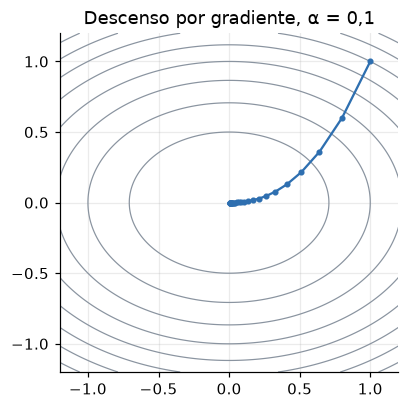

✔ el primer paso da (0,8; 0,6) y f = 1,36


In [5]:
# Define el coste cuadrático f(x,y) = x² + 2y² que se quiere reducir.
f = lambda v: v[0]**2 + 2*v[1]**2
# Diap. 9. v guarda (x, y). Cada componente de ∇f = (2x, 4y) deriva respecto de una variable con la otra fija.
grad = lambda v: np.array([2*v[0], 4*v[1]])
# Fija el punto inicial (1,1) y el tamaño de paso α = 0.1 de la diap. 9.
v = np.array([1.0, 1.0]); alpha = 0.1
# Restar α∇f mueve v en la dirección de descenso. α fija el tamaño del paso.
v1 = v - alpha*grad(v)
# Compara el valor del coste inicial con el obtenido tras una actualización.
print("Un paso desde (1,1):", v1, "  f pasa de", f(v), "a", round(f(v1), 4))
# Guarda una copia del punto inicial para incluirlo en la trayectoria.
tray = [v.copy()]
# Repite el descenso 25 veces para observar la evolución hacia el mínimo.
for _ in range(25):
    # Los factores por coordenada son 1 − 2α y 1 − 4α.
    # Ambos deben tener módulo menor que 1 para converger desde (1,1), igual que en Euler (diap. 26).
    v = v - alpha*grad(v); tray.append(v.copy())
for paso, (x, y) in enumerate(tray):
    print(f"Paso {paso:2d} | x = {x:.8g} | y = {y:.8g}")
# Convierte la lista en una matriz con una fila por iteración y una columna por coordenada.
tray = np.array(tray)
# Construye una rejilla de pares (x,y) para evaluar el coste en el plano.
X, Y = np.meshgrid(np.linspace(-1.2, 1.2, 200), np.linspace(-1.2, 1.2, 200))
# Dibuja ocho niveles del coste. Cada curva une puntos con el mismo f(x,y).
plt.figure(figsize=(4.5, 4)); plt.contour(X, Y, X**2 + 2*Y**2, levels=8, colors=GRIS, linewidths=0.8)
# Superpone los pasos del algoritmo con la misma escala en ambos ejes.
plt.plot(tray[:, 0], tray[:, 1], "o-", color=AZUL, ms=3); plt.gca().set_aspect("equal"); plt.title("Descenso por gradiente, α = 0,1"); plt.show()
# Comprueba tanto las coordenadas del primer paso como el coste f(v₁) que les corresponde.
assert np.allclose(v1, [0.8, 0.6]) and abs(f(v1) - 1.36) < 1e-12
# Muestra los valores comprobados del primer paso.
ok("el primer paso da (0,8; 0,6) y f = 1,36")

**Pruébelo.** Cambie `alpha` a 0,45 y luego a 0,55. ¿Por qué con 0,55 diverge? (Pista: diapositiva 26, $\alpha<2/L$ con $L=4$.)

## 0.4 Encontrar un mínimo: ¿cuántos servidores? (diapositiva 10)
$C(n)=2n+50/n$. Analíticamente $n^*=5$, $C=20$.

Candidatos: [5]   C'' en n* = 4/5
Numérico: n* = 5.0000, C = 20.0000


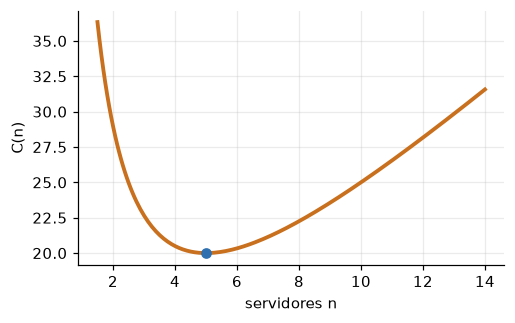

✔ mínimo en n = 5 con C = 20


In [6]:
# Declara n positivo porque representa una cantidad de servidores y aparece en un denominador.
n = sp.symbols("n", positive=True)
# Diap. 10. C(n) suma el coste de contratar n servidores (2n) y el coste de espera (50/n).
C = 2*n + 50/n
# Se busca C′(n) = 2 − 50/n² = 0 con n > 0. Como C″(n) = 100/n³ > 0, el candidato es un mínimo.
n_star = sp.solve(sp.diff(C, n), n)
# Evalúa C″ en el candidato para mostrar que la curvatura allí es positiva.
print("Candidatos:", n_star, "  C'' en n* =", sp.diff(C, n, 2).subs(n, n_star[0]))
# La búsqueda acotada minimiza la misma función en el intervalo continuo [1, 20].
res = minimize_scalar(lambda m: 2*m + 50/m, bounds=(1, 20), method="bounded")
# Muestra el argumento res.x que minimiza el coste y el valor res.fun que alcanza.
print(f"Numérico: n* = {res.x:.4f}, C = {res.fun:.4f}")
# Genera valores de n alrededor del mínimo para trazar la curva.
nn = np.linspace(1.5, 14, 200)
# Dibuja C(n) y marca el mínimo analítico en (5,20).
plt.figure(figsize=(5, 3)); plt.plot(nn, 2*nn + 50/nn, color=NARANJA, lw=2.5); plt.scatter([5], [20], color=AZUL, zorder=5)
# Identifica la cantidad de servidores y el coste en sus respectivos ejes.
plt.xlabel("servidores n"); plt.ylabel("C(n)"); plt.show()
# Verifica que la solución simbólica es 5 y que la numérica coincide dentro de la tolerancia.
assert n_star == [5] and abs(res.x - 5) < 1e-4
# Comunica el punto donde se alcanza el menor coste.
ok("mínimo en n = 5 con C = 20")

## 0.5 Integrales e integración por partes (diapositivas 11–12)

In [7]:
# Diap. 11. quad(...)[0] devuelve la estimación de la integral definida, que acumula la tasa en [0,1].
print("∫0^1 t dt     =", quad(lambda s: s, 0, 1)[0])
# Integra t² en [0,1] para comprobar numéricamente el resultado 1/3 de la regla de la potencia.
print("∫0^1 t² dt    =", quad(lambda s: s**2, 0, 1)[0])
# Diap. 12. Por partes, con a = t y b = exp(t), la integral vale [t·exp(t)]₀¹ − ∫₀¹ exp(t) dt.
print("∫0^1 t·e^t dt =", quad(lambda s: s*np.exp(s), 0, 1)[0], "(por partes da exactamente 1)")
# Integra t·exp(t) simbólicamente para obtener un valor exacto.
print("Simbólico     =", sp.integrate(t*sp.exp(t), (t, 0, 1)))
# La integral como suma de rectángulos (puente con el tiempo discreto)
for N in [10, 100, 1000]:
    # Cada rectángulo tiene ancho Δt = 1/N y altura evaluada en el punto medio tₖ = (k+½)Δt.
    # Sumar altura por ancho aproxima la integral (diap. 11).
    dt = 1/N; tk = (np.arange(N) + 0.5)*dt
    # Suma las áreas de los rectángulos y muestra cómo cambia la aproximación al refinar la partición.
    print(f"Suma con {N:>4} pasos: {np.sum(tk*np.exp(tk))*dt:.6f}")
# Exige que la integral simbólica sea exactamente 1, como resulta de la integración por partes.
assert sp.integrate(t*sp.exp(t), (t, 0, 1)) == 1
# Señala el valor comprobado de la integral definida.
ok("∫ t eᵗ de 0 a 1 = 1")

∫0^1 t dt     = 0.5
∫0^1 t² dt    = 0.33333333333333337
∫0^1 t·e^t dt = 1.0 (por partes da exactamente 1)
Simbólico     = 1
Suma con   10 pasos: 0.998152
Suma con  100 pasos: 0.999982
Suma con 1000 pasos: 1.000000
✔ ∫ t eᵗ de 0 a 1 = 1


## 0.6 Ecuación diferencial y exponencial (diapositivas 13–14)
$\dot x=-0{,}5x$, $x(0)=8$. Solución $x(t)=8e^{-0{,}5t}$; $x(2)\approx2{,}94$.

In [8]:
# Declara x como función simbólica desconocida para poder escribir x(t) y su derivada.
xt = sp.Function("x")
# Diap. 13. Eq expresa ẋ = −x/2 y la condición inicial x(0) = 8 fija la constante de la solución exponencial.
sol = sp.dsolve(sp.Eq(xt(t).diff(t), -sp.Rational(1, 2)*xt(t)), ics={xt(0): 8})
# Muestra la expresión exacta que cumple la ecuación diferencial y la condición inicial.
print("Solución simbólica:", sol)
# El integrador recibe la velocidad f(t,x) = −0.5x. La salida continua permite evaluar la solución en t = 2.
num = solve_ivp(lambda s, z: -0.5*z, (0, 6), [8.0], dense_output=True, rtol=1e-9)
# Compara la integración numérica en t = 2 con la fórmula exacta 8exp(−1).
print(f"x(2) numérico = {num.sol(2)[0]:.4f}   exacto = {8*np.exp(-1):.4f}")
# Diap. 14. Si x = x₀ exp(at) y x/x₀ = 2, el tiempo de duplicación es ln(2)/a.
print(f"Tiempo de duplicación con a = 0,1: ln2/0,1 = {np.log(2)/0.1:.2f} días")
# Comprueba que el error absoluto de la aproximación en t = 2 es menor que 10⁻⁶.
assert abs(num.sol(2)[0] - 8*np.exp(-1)) < 1e-6
# Señala que la integración numérica concuerda con la solución exacta.
ok("la solución numérica coincide con la exacta")

Solución simbólica: Eq(x(t), 8*exp(-t/2))
x(2) numérico = 2.9430   exacto = 2.9430
Tiempo de duplicación con a = 0,1: ln2/0,1 = 6.93 días
✔ la solución numérica coincide con la exacta


## 0.7 Matrices y autovalores (diapositivas 15–16)

In [9]:
# Diap. 15. Cada fila de A calcula una componente del estado siguiente xₖ₊₁ = Axₖ.
# La segunda fila suma defectos nuevos debidos a la deuda y el 90 % de los defectos previos.
A = np.array([[1.04, 0.0], [0.1, 0.9]]); xv = np.array([20.0, 5.0])
# Multiplica A por el estado inicial y muestra la deuda y los defectos del sprint siguiente.
print("A·x =", A @ xv)
# Diap. 16. En discreto, un modo decae si |λ| < 1. El autovalor 1.04 de A indica un modo que crece.
print("Autovalores de A (deuda/defectos):", np.linalg.eigvals(A))
# Para esta matriz triangular, los autovalores son los de la diagonal. En la dinámica continua ẋ = A2·x, ambos modos decaen.
A2 = np.array([[-1.0, 1.0], [0.0, -2.0]])
# Calcula numéricamente los dos autovalores para compararlos con la diagonal de A2.
print("Autovalores de [[-1,1],[0,-2]]:", np.linalg.eigvals(A2))
# Comprueba el producto matricial y compara los autovalores ordenados con los valores exactos.
assert np.allclose(A @ xv, [20.8, 6.5]) and np.allclose(sorted(np.linalg.eigvals(A2)), [-2, -1])
# Resume el estado siguiente y los autovalores comprobados.
ok("A·x = (20,8; 6,5); autovalores −1 y −2")

A·x = [20.8  6.5]
Autovalores de A (deuda/defectos): [0.9 +0.j 1.04+0.j]
Autovalores de [[-1,1],[0,-2]]: [-1.+0.j -2.+0.j]
✔ A·x = (20,8; 6,5); autovalores −1 y −2


## 0.8 Valor esperado (diapositiva 17)

In [10]:
# Diap. 17. Cada demanda w[i] tiene probabilidad pw[i]. La esperanza suma los valores ponderados por esas probabilidades.
w = np.array([0, 1, 2, 3]); pw = np.array([0.1, 0.3, 0.4, 0.2])
# Para el coste de faltantes se calcula primero 3·max(w−2, 0) en cada escenario y después se promedia.
Ew = np.sum(w*pw); Efalta = np.sum(pw*3*np.maximum(w - 2, 0))
# Simulación de Monte Carlo: promediar muchos futuros posibles
# Se muestrea con la misma distribución. El promedio de las muestras aproxima la esperanza teórica.
muestras = np.random.default_rng(0).choice(w, size=200_000, p=pw)
# Compara la esperanza ponderada de la demanda con la media de las muestras.
print(f"E[w] = {Ew:.2f}  (simulado {muestras.mean():.3f})")
# Aplica el coste de faltantes a cada muestra y compara su promedio con la esperanza teórica.
print(f"E[3·máx(w−2,0)] = {Efalta:.2f}  (simulado {np.mean(3*np.maximum(muestras - 2, 0)):.3f})")
# Verifica la demanda y el coste esperados con una tolerancia para el redondeo numérico.
assert abs(Ew - 1.7) < 1e-12 and abs(Efalta - 0.6) < 1e-12
# Muestra los dos valores esperados que se comprobaron.
ok("E[w] = 1,7 y coste esperado de faltantes = 0,6")

E[w] = 1.70  (simulado 1.697)
E[3·máx(w−2,0)] = 0.60  (simulado 0.594)
✔ E[w] = 1,7 y coste esperado de faltantes = 0,6


## 0.9 Multiplicadores de Lagrange (diapositiva 18)
$\min x^2+y^2$ s.a. $x+y=4$.

In [11]:
# Declara las incógnitas simbólicas x, y y el multiplicador λ de la restricción.
xs, ys, lam = sp.symbols("x y lambda")
# Diap. 18. El multiplicador λ incorpora la restricción x + y = 4 mediante el residuo x + y − 4.
L = xs**2 + ys**2 + lam*(xs + ys - 4)
# Las condiciones de estacionariedad son 2x + λ = 0, 2y + λ = 0 y x + y − 4 = 0.
# La tercera ecuación sale de derivar L respecto de λ.
sol = sp.solve([sp.diff(L, v_) for v_ in (xs, ys, lam)], (xs, ys, lam), dict=True)[0]
# Sustituye los valores óptimos de x e y en el coste original para obtener el mínimo.
print("Solución:", sol, "  coste mínimo:", (xs**2 + ys**2).subs(sol))
# precio sombra: relajar la restricción a x + y = 5
# Con L = x² + y² + λ(x+y−b), la sensibilidad local del mínimo a b es −λ.
# Pasar de b = 4 a 5 produce un cambio finito que se compara con esa aproximación.
v5 = minimize(lambda z: z[0]**2 + z[1]**2, [0, 0], constraints={"type": "eq", "fun": lambda z: z[0] + z[1] - 5}).fun
# Compara el aumento real del coste al exigir x+y = 5 con la sensibilidad local en x+y = 4.
print(f"Con x + y = 5 el mínimo es {v5:.2f}: subió {v5 - 8:.2f} ≈ |λ| = 4")
# Comprueba el valor y el signo del multiplicador con la convención usada en L.
assert sol[lam] == -4
# Resume el punto óptimo y su multiplicador.
ok("x = y = 2, λ = −4")

Solución: {lambda: -4, x: 2, y: 2}   coste mínimo: 8
Con x + y = 5 el mínimo es 12.50: subió 4.50 ≈ |λ| = 4
✔ x = y = 2, λ = −4


---
# Bloque 1 · Sistemas dinámicos
## 1.1 Crecimiento de usuarios y enfriamiento de un servidor (diapositivas 22–23)

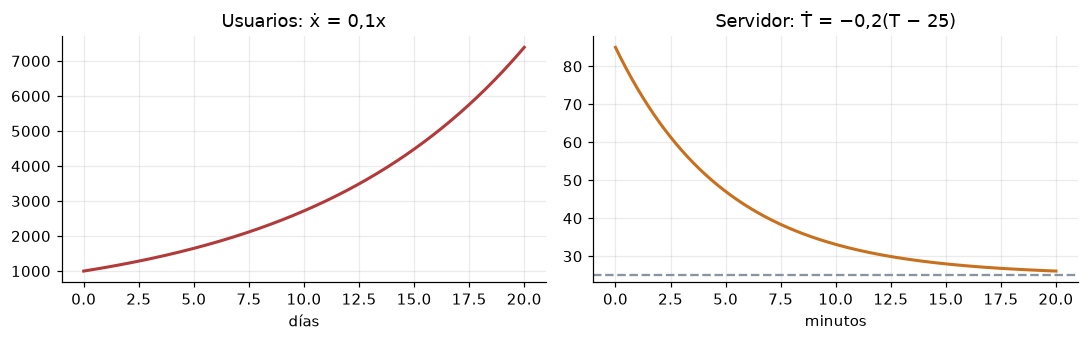

Usuarios a los 10 días: 2718;  a los 100 días: 22,026,466 (¡poco realista!)
Temperatura a los 5 minutos: 47.1 °C
✔ ejemplos 1 y 2 reproducidos


In [12]:
# Genera 400 instantes de evaluación entre 0 y 20 para ambas curvas.
tt = np.linspace(0, 20, 400)
# Diap. 22. ẋ = 0.1x da crecimiento exponencial a partir de x(0) = 1000.
usuarios = 1000*np.exp(0.1*tt)
# Diap. 23. El exceso sobre los 25 °C ambientales obedece ẏ = −0.2y.
# Al sumar otra vez la temperatura ambiente se obtiene T(t) = 25 + (85−25)exp(−0.2t).
Tserv = 25 + 60*np.exp(-0.2*tt)
# Crea dos ejes en paralelo para mostrar por separado el crecimiento y el enfriamiento.
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
# Dibuja el número de usuarios en función del tiempo medido en días.
ax[0].plot(tt, usuarios, color=ROJO, lw=2); ax[0].set_title("Usuarios: ẋ = 0,1x"); ax[0].set_xlabel("días")
# Dibuja la temperatura en minutos y marca 25 °C como referencia de equilibrio.
ax[1].plot(tt, Tserv, color=NARANJA, lw=2); ax[1].axhline(25, color=GRIS, ls="--"); ax[1].set_title("Servidor: Ṫ = −0,2(T − 25)"); ax[1].set_xlabel("minutos")
# Ajusta la separación entre los dos ejes y muestra la figura.
plt.tight_layout(); plt.show()
# Evalúa el modelo de usuarios en 10 y 100 días para mostrar el alcance de la extrapolación.
print(f"Usuarios a los 10 días: {1000*np.e:.0f};  a los 100 días: {1000*np.exp(10):,.0f} (¡poco realista!)")
# Sustituye t = 5 minutos en la fórmula de enfriamiento, cuyo exponente es entonces −1.
print(f"Temperatura a los 5 minutos: {25 + 60*np.exp(-1):.1f} °C")
# Señala que se reprodujeron los dos ejemplos de la guía.
ok("ejemplos 1 y 2 reproducidos")

## 1.2 Cola de solicitudes: simulación con servidores variables (diapositiva 24)
$\dot Q=\lambda-\mu n$, con $Q\ge0$, $\lambda=1000$/s y $\mu=120$ por servidor.

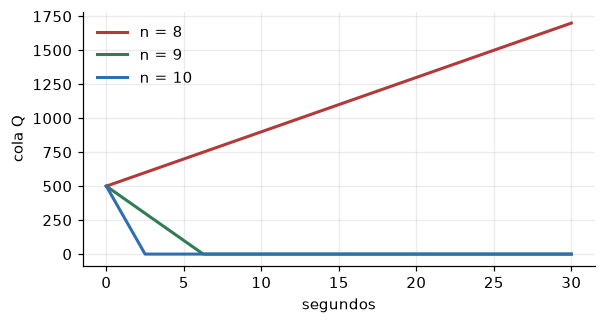

✔ con 8 servidores la cola crece; con 9 se vacía
paso=  0  t= 0.0 s  Q=500
paso=  1  t= 0.1 s  Q=504
paso=  2  t= 0.2 s  Q=508
paso=  3  t= 0.3 s  Q=512
paso=  4  t= 0.4 s  Q=516
paso=  5  t= 0.5 s  Q=520
paso=  6  t= 0.6 s  Q=524
paso=  7  t= 0.7 s  Q=528
paso=  8  t= 0.8 s  Q=532
paso=  9  t= 0.9 s  Q=536
paso= 10  t= 1.0 s  Q=540
paso= 11  t= 1.1 s  Q=544
paso= 12  t= 1.2 s  Q=548
paso= 13  t= 1.3 s  Q=552
paso= 14  t= 1.4 s  Q=556
paso= 15  t= 1.5 s  Q=560
paso= 16  t= 1.6 s  Q=564
paso= 17  t= 1.7 s  Q=568
paso= 18  t= 1.8 s  Q=572
paso= 19  t= 1.9 s  Q=576
paso= 20  t= 2.0 s  Q=580
paso= 21  t= 2.1 s  Q=584
paso= 22  t= 2.2 s  Q=588
paso= 23  t= 2.3 s  Q=592
paso= 24  t= 2.4 s  Q=596
paso= 25  t= 2.5 s  Q=600
paso= 26  t= 2.6 s  Q=604
paso= 27  t= 2.7 s  Q=608
paso= 28  t= 2.8 s  Q=612
paso= 29  t= 2.9 s  Q=616
paso= 30  t= 3.0 s  Q=620
paso= 31  t= 3.1 s  Q=624
paso= 32  t= 3.2 s  Q=628
paso= 33  t= 3.3 s  Q=632
paso= 34  t= 3.4 s  Q=636
paso= 35  t= 3.5 s  Q=640
paso= 36  t= 3.

In [13]:
# Define el simulador con un número fijo de servidores por corrida y parámetros de llegada y servicio.
def simular_cola(n_servidores, lam=1000, mu=120, Q0=500, T=30, dt=0.1):
    # Inicializa el historial con las solicitudes que ya estaban en cola cuando t = 0.
    Q = [Q0]
    # Ejecuta un paso por cada intervalo completo de tamaño dt dentro de T.
    for _ in range(int(T/dt)):
        # Diap. 24 y 26. Euler añade Δt por el balance λ − μn, medido en solicitudes por segundo.
        # max(0, ...) mantiene la cola en cero si la capacidad supera las solicitudes disponibles.
        Q.append(max(0.0, Q[-1] + dt*(lam - mu*n_servidores)))
    # Devuelve la cola inicial y la obtenida en cada paso como un arreglo numérico.
    return np.array(Q)
# Abre la figura donde se compararán los tamaños de cola para distintas capacidades.
plt.figure(figsize=(6, 3))
# Con 8 servidores la tasa neta es +40/s. Con 9 es −80/s mientras haya solicitudes en espera.
for n_, col in [(8, ROJO), (9, VERDE), (10, AZUL)]:
    # Grafica los 301 valores de cada corrida, incluido el inicial, con los parámetros predeterminados.
    plt.plot(np.arange(301)*0.1, simular_cola(n_), color=col, lw=2, label=f"n = {n_}")
# Rotula el tiempo en segundos y usa la leyenda para identificar el número de servidores.
plt.xlabel("segundos"); plt.ylabel("cola Q"); plt.legend(frameon=False); plt.show()
# Verifica que 8 servidores dejan más solicitudes que al inicio y que 9 vacían la cola.
assert simular_cola(8)[-1] > 500 and simular_cola(9)[-1] == 0
# Indica el efecto de aumentar la capacidad de 8 a 9 servidores.
ok("con 8 servidores la cola crece; con 9 se vacía")
for paso, q in enumerate(simular_cola(8)):
    print(f"paso={paso:3d}  t={paso * 0.1:4.1f} s  Q={q:g}")

**Pruébelo.** Haga que `lam` cambie con el tiempo (por ejemplo, un pico a los 10 segundos). ¿Cuántos servidores harían falta?
Esa pregunta, decidir `n(t)`, es un problema de **control óptimo** (Bloque 3).

## 1.3 Deuda técnica sprint a sprint y política en lazo cerrado (diapositiva 25)

Sin refactorizar: [100.   115.   130.75 147.29 164.65 182.88 202.03 222.13 243.24 265.4
 288.67 313.1  338.76]
Regla u = 0,3 D : [100.    85.    73.75  65.31  58.98  54.24  50.68  48.01  46.01  44.51
  43.38  42.53  41.9 ] → equilibrio 40


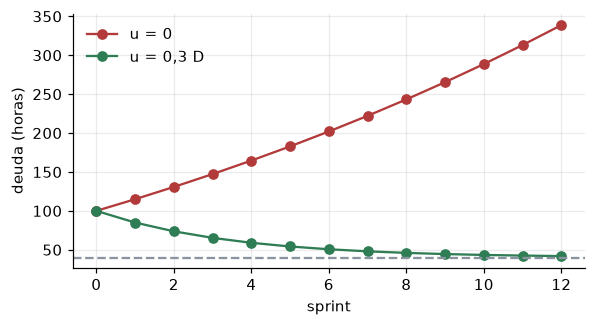

✔ tabla de la diapositiva 25 reproducida


In [14]:
# Define una simulación por sprints que recibe la política de refactorización como función.
def deuda(regla, D0=100, sprints=12):
    # Guarda D₀ como primer elemento del historial de deuda.
    D = [D0]
    # Actualiza la deuda una vez por sprint usando el estado más reciente.
    for _ in range(sprints):
        # Diap. 25. Dₖ₊₁ = 1.05Dₖ + 10 − uₖ suma crecimiento y deuda nueva, y resta la refactorización.
        D.append(1.05*D[-1] + 10 - regla(D[-1]))
    # Devuelve el historial de deuda, incluido el valor inicial, como un arreglo.
    return np.array(D)
# La regla uₖ = 0.3Dₖ se aplica al estado actual y da Dₖ₊₁ = 0.75Dₖ + 10.
# El factor |0.75| < 1 hace que la deuda se acerque al punto fijo D* = 10/(1−0.75).
D_sin, D_con = deuda(lambda D: 0), deuda(lambda D: 0.3*D)
# Muestra los primeros cuatro valores sin refactorización, redondeados a dos decimales.
print("Sin refactorizar:", np.round(D_sin[:13], 2))
# Muestra los primeros cuatro valores con realimentación y señala el equilibrio de 40 horas.
print("Regla u = 0,3 D :", np.round(D_con[:13], 2), "→ equilibrio 40")
# Dibuja ambas trayectorias para comparar el efecto de aplicar uₖ = 0.3Dₖ.
plt.figure(figsize=(6, 3)); plt.plot(D_sin, "o-", color=ROJO, label="u = 0"); plt.plot(D_con, "o-", color=VERDE, label="u = 0,3 D")
# Marca el equilibrio como línea horizontal y rotula los ejes en sprints y horas.
plt.axhline(40, color=GRIS, ls="--"); plt.xlabel("sprint"); plt.ylabel("deuda (horas)"); plt.legend(frameon=False); plt.show()
# Compara los valores iniciales con la tabla y comprueba que la política se acerca a las 40 horas.
assert np.allclose(D_sin[:4], [100, 115, 130.75, 147.2875]) and abs(D_con[-1] - 40) < 4
# Señala que los resultados reproducen el ejemplo de deuda técnica.
ok("tabla de la diapositiva 25 reproducida")

## 1.4 Método de Euler y su condición de estabilidad (diapositiva 26)

Euler Δt=0,5: [0.5   0.25  0.125 0.062]   exacta: [0.607 0.368 0.223 0.135]


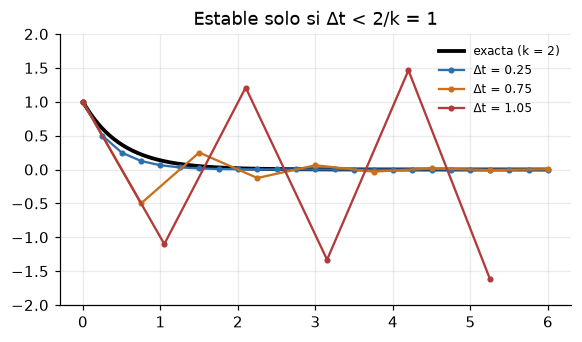

✔ Euler reproduce la tabla y diverge con Δt > 2/k


In [15]:
# Define el método de Euler para ẋ = −kx con paso dt, horizonte T y valor inicial x₀.
def euler(k, dt, T=6, x0=1.0):
    # Diap. 26. Sustituir f(x) = −kx en Euler da xₖ₊₁ = xₖ + (-kxₖ)Δt = (1−kΔt)xₖ.  xi = x0*(1−kΔt)^i  
    # Cada paso vuelve a multiplicar por el mismo factor. Por eso el exponente cuenta los pasos transcurridos.
    n_ = int(T/dt);                  # Número de pasos completos
    pasos = np.arange(n_ + 1)        # Índices: 0, 1, ..., n_
    tiempos = pasos * dt
    valores = x0 * (1 - k * dt)**pasos
    return tiempos, valores
# Reproduce el caso de la diap. 26 con tasa de decaimiento 1 y paso de 0.5.
t05, x05 = euler(1, 0.5, T=2)
# Compara las aproximaciones tras cada paso con exp(−t) evaluada en esos mismos tiempos.
print("Euler Δt=0,5:", np.round(x05[1:], 3), "  exacta:", np.round(np.exp(-t05[1:]), 3))
# Crea una figura y una rejilla de tiempos más fina para dibujar la solución exacta.
plt.figure(figsize=(6, 3.2)); ts = np.linspace(0, 6, 300)
# Dibuja la referencia x(t) = exp(−2t) para comparar los tres pasos de Euler.
plt.plot(ts, np.exp(-2*ts), color="k", lw=2.5, label="exacta (k = 2)")
# Con k = 2, 0 < Δt < 1 asegura |1−kΔt| < 1.
# Un factor negativo hace alternar el signo. Si su módulo excede 1, la magnitud crece.
for dt, col in [(0.25, AZUL), (0.75, NARANJA), (1.05, ROJO)]:
    # Simula Euler para el paso elegido y marca las aproximaciones en los tiempos de la rejilla.
    tq, xq = euler(2, dt); plt.plot(tq, xq, "o-", color=col, ms=3, label=f"Δt = {dt}")
# Limita el rango vertical para comparar las curvas e identifica cada tamaño de paso.
plt.ylim(-2, 2); plt.legend(frameon=False, fontsize=8); plt.title("Estable solo si Δt < 2/k = 1"); plt.show()
# Comprueba las cuatro aproximaciones de Euler de la diapositiva, excluido el valor inicial.
assert np.allclose(x05[1:], [0.5, 0.25, 0.125, 0.0625])
# Resume la reproducción de la tabla y la divergencia al superar el umbral.
ok("Euler reproduce la tabla y diverge con Δt > 2/k")

In [16]:
for paso_euler in (0.25, 0.75, 1.05):
    tiempos, valores = euler(2, paso_euler)
    print(f"\ndt = {paso_euler}")
    for i, (t, x) in enumerate(zip(tiempos[:5], valores[:5])):
        print(f"i={i:2d}  tq={t:5.2f}  xq={x: .8g}")


dt = 0.25
i= 0  tq= 0.00  xq= 1
i= 1  tq= 0.25  xq= 0.5
i= 2  tq= 0.50  xq= 0.25
i= 3  tq= 0.75  xq= 0.125
i= 4  tq= 1.00  xq= 0.0625

dt = 0.75
i= 0  tq= 0.00  xq= 1
i= 1  tq= 0.75  xq=-0.5
i= 2  tq= 1.50  xq= 0.25
i= 3  tq= 2.25  xq=-0.125
i= 4  tq= 3.00  xq= 0.0625

dt = 1.05
i= 0  tq= 0.00  xq= 1
i= 1  tq= 1.05  xq=-1.1
i= 2  tq= 2.10  xq= 1.21
i= 3  tq= 3.15  xq=-1.331
i= 4  tq= 4.20  xq= 1.4641


## 1.5 Estabilidad, Lyapunov y línea de fase (diapositivas 27–28)

dV/dt = -2*x**4
Partiendo de x = 2, en t = 50: x = 0.1000 (tiende a 0, aunque lentamente)


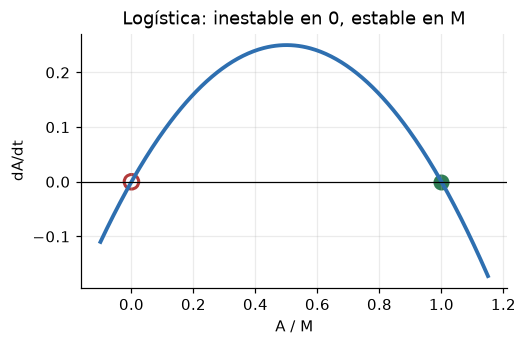

✔ Lyapunov y línea de fase


In [17]:
# Lyapunov para ẋ = -x³ con V = x²: dV/dt = 2x·(-x³) = -2x⁴ < 0
# Declara la variable real x para calcular la derivada de Lyapunov con SymPy.
xq = sp.symbols("x", real=True)
# Diap. 27. La linealización tiene derivada cero en el origen. Con V = x², la regla de la cadena
# da V̇ = −2x⁴, estrictamente negativa fuera del equilibrio, y muestra estabilidad asintótica.
print("dV/dt =", sp.simplify(sp.diff(xq**2, xq)*(-xq**3)))
# Integra ẋ = −x³ desde x(0) = 2 para visualizar el decaimiento que predice Lyapunov.
sol = solve_ivp(lambda s, z: -z**3, (0, 50), [2.0], dense_output=True)
# Lee el último valor guardado de la primera componente, correspondiente a t = 50.
print(f"Partiendo de x = 2, en t = 50: x = {sol.y[0, -1]:.4f} (tiende a 0, aunque lentamente)")
# Crea una rejilla del estado normalizado A/M que incluye ambos equilibrios.
A_ = np.linspace(-0.1, 1.15, 300)
# Diap. 28. Si z = A/M y r = 1, el campo normalizado es ż = z(1−z).
# El signo del campo aleja la trayectoria de z = 0 y la acerca a z = 1 para z > 0.
plt.figure(figsize=(5, 3)); plt.plot(A_, A_*(1 - A_), color=AZUL, lw=2.5); plt.axhline(0, color="k", lw=0.8)
# Marca con un punto abierto el equilibrio inestable y con uno lleno el estable.
plt.scatter([0], [0], s=90, facecolors="none", edgecolors=ROJO, lw=2); plt.scatter([1], [0], s=90, color=VERDE)
# Identifica el estado normalizado y el campo de velocidades en la línea de fase.
plt.xlabel("A / M"); plt.ylabel("dA/dt"); plt.title("Logística: inestable en 0, estable en M"); plt.show()
# Cierra el ejemplo que combina un criterio de estabilidad y el signo del campo.
ok("Lyapunov y línea de fase")

In [18]:
for i, (t_i, x_i) in enumerate(zip(sol.t[:14], sol.y[0, :14])):
    print(f"i={i}  t={t_i:.6f}  x={x_i:.6f}")

i=0  t=0.000000  x=2.000000
i=1  t=0.046202  x=1.708980
i=2  t=0.166334  x=1.311793
i=3  t=0.339744  x=1.038554
i=4  t=0.631177  x=0.814298
i=5  t=1.097978  x=0.640320
i=6  t=1.856492  x=0.503066
i=7  t=3.083693  x=0.395333
i=8  t=5.071867  x=0.310643
i=9  t=8.291745  x=0.244098
i=10  t=13.507311  x=0.191802
i=11  t=21.955795  x=0.150706
i=12  t=35.642554  x=0.118412
i=13  t=50.000000  x=0.099986


---
# Bloque 2 · Cálculo de variaciones
## 2.1 Un funcional asigna un número a cada trayectoria (diapositiva 31)
$J[x]=\int_0^1\dot x^2\,dt$ para tres trayectorias de 0 a 1.

In [19]:
# Define un funcional que recibe una función velocidad, es decir, una trayectoria completa de ẋ.
def J_esfuerzo(xdot):
    # Diap. 31. El funcional recibe toda la función velocidad ẋ(t) y devuelve el esfuerzo acumulado J[x] = ∫₀¹ ẋ² dt.
    return quad(lambda s: xdot(s)**2, 0, 1)[0]
# Las tres curvas tienen los mismos extremos. Se integran sus pendientes 1, 2t y 3t elevadas al cuadrado.
for nombre, xd, esperado in [("x = t", lambda s: 1.0, 1), ("x = t²", lambda s: 2*s, 4/3), ("x = t³", lambda s: 3*s**2, 9/5)]:
    # Imprime el esfuerzo calculado por cuadratura junto al valor analítico de cada camino.
    print(f"{nombre:7s} J = {J_esfuerzo(xd):.4f}  (esperado {esperado:.4f})")
# Resume la comparación de las tres trayectorias con extremos comunes.
ok("la recta tiene el menor esfuerzo de las tres")

x = t   J = 1.0000  (esperado 1.0000)
x = t²  J = 1.3333  (esperado 1.3333)
x = t³  J = 1.8000  (esperado 1.8000)
✔ la recta tiene el menor esfuerzo de las tres


## 2.2 Euler–Lagrange automático con `sympy` (diapositivas 34–38)
`sympy` construye y resuelve $\frac{\partial L}{\partial x}-\frac{d}{dt}\frac{\partial L}{\partial \dot x}=0$.

In [20]:
# Importa la utilidad de SymPy que construye ecuaciones de Euler–Lagrange.
from sympy.calculus.euler import euler_equations
# Representa la trayectoria desconocida como la función simbólica x(t).
X = sp.Function("x")
# Define una rutina que recibe el integrando L y las condiciones de frontera.
def resolver_EL(L, ics):
    # Diap. 34–35. La primera variación, tras integrar por partes con extremos fijos,
    # da ∂L/∂x − d/dt(∂L/∂ẋ) = 0. SymPy construye esa ecuación diferencial.
    ec = euler_equations(L, X(t), t)[0]
    # Las condiciones x(0) y x(1) determinan las constantes de integración de la trayectoria.
    return ec, sp.dsolve(ec, X(t), ics=ics)
# En los dos primeros casos L no depende de x y ∂L/∂ẋ es constante.
# Al añadir x² se obtiene ẍ = x y aparecen sinh(t) y cosh(t) (diap. 35–37).
for titulo, L in [("esfuerzo  L = ẋ²", X(t).diff(t)**2),
                  # Para longitud de arco, cada elemento de la curva mide √(1+ẋ²) dt (diap. 36).
                  ("camino más corto  L = √(1+ẋ²)", sp.sqrt(1 + X(t).diff(t)**2)),
                  # El último integrando penaliza tanto la velocidad ẋ como el nivel x (diap. 37).
                  ("velocidad vs nivel  L = ẋ² + x²", X(t).diff(t)**2 + X(t)**2)]:
    # Resuelve cada ecuación con los puntos fijos x(0) = 0 y x(1) = 1.
    ec, so = resolver_EL(L, {X(0): 0, X(1): 1})
    # Muestra por separado el lado izquierdo de la ecuación igualada a cero y la trayectoria obtenida.
    print(f"{titulo}\n   ecuación: {sp.simplify(ec.lhs)} = 0\n   solución: {sp.simplify(so.rhs)}\n")

ValueError: 
Can't calculate derivative wrt 4.20000000000000.

## 2.3 Comprobación numérica: optimizar la trayectoria directamente (diapositiva 37)
Discretizamos $x(t)$ en 50 puntos y minimizamos $\int(\dot x^2+x^2)\,dt$ sin usar Euler–Lagrange.
El resultado debe coincidir con $x^*(t)=\sinh t/\sinh 1$ y $J^*=\coth 1\approx1{,}313$.

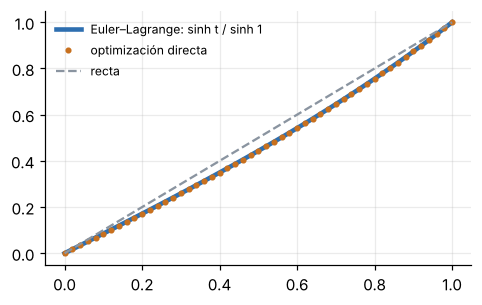

J numérico = 1.3130   coth(1) = 1.3130   recta = 1.3333
✔ la optimización directa confirma Euler–Lagrange


In [ ]:
# Diap. 37. N intervalos generan N+1 nodos. La discretización representa x(t) por sus valores en esos nodos.
N = 50; dt = 1/N; tg = np.linspace(0, 1, N + 1)
# Define el coste discreto como función de las alturas que se pueden ajustar en los nodos interiores.
def J_disc(interior):
    # Se fijan x(0) = 0 y x(1) = 1. Solo los valores interiores forman el vector que se optimiza.
    xg = np.concatenate([[0.0], interior, [1.0]])
    # En cada intervalo, v_ aproxima ẋ por la pendiente y xm aproxima x por el promedio de los dos extremos.
    v_ = np.diff(xg)/dt; xm = (xg[1:] + xg[:-1])/2
    # La suma de (ẋ² + x²)Δt aproxima el funcional de la diapositiva.
    return np.sum((v_**2 + xm**2)*dt)
# BFGS parte de la recta x = t. El coste se compara con el de la solución de Euler–Lagrange, J* = coth(1).
res = minimize(J_disc, tg[1:-1], method="BFGS")
# Reconstruye la trayectoria optimizada al agregar sus dos valores de frontera.
xg = np.concatenate([[0], res.x, [1]])
# Dibuja la solución analítica x*(t) = sinh(t)/sinh(1) para usarla como referencia.
plt.figure(figsize=(5, 3)); plt.plot(tg, np.sinh(tg)/np.sinh(1), color=AZUL, lw=3, label="Euler–Lagrange: sinh t / sinh 1")
# Superpone los nodos optimizados y la recta x = t, que también cumple ambos extremos.
plt.plot(tg, xg, ".", color=NARANJA, label="optimización directa"); plt.plot(tg, tg, "--", color=GRIS, label="recta")
# Muestra la leyenda para distinguir la solución analítica, la numérica y la recta.
plt.legend(frameon=False, fontsize=8); plt.show()
# Compara el coste numérico con coth(1) = 1/tanh(1) y con el coste de la recta.
print(f"J numérico = {res.fun:.4f}   coth(1) = {1/np.tanh(1):.4f}   recta = {4/3:.4f}")
# Verifica que el coste discretizado difiere del continuo en menos de 10⁻³.
assert abs(res.fun - 1/np.tanh(1)) < 1e-3
# Señala que la minimización directa reproduce el coste predicho por Euler–Lagrange.
ok("la optimización directa confirma Euler–Lagrange")

## 2.4 Punto final libre (diapositiva 38)
$\min\int_0^1(\dot x^2+2x)\,dt$, $x(0)=0$, $x(1)$ libre ⇒ $x^*=t^2/2-t$, $J^*=-1/3$.

In [ ]:
# Define el funcional discretizado para un problema en el que se puede elegir el estado final.
def J_libre(z):
    # Diap. 38. Se fija x(0) = 0. El vector z incluye x(1), por lo que el mínimo elige también el extremo final.
    xg = np.concatenate([[0.0], z]); v_ = np.diff(xg)/dt; xm = (xg[1:] + xg[:-1])/2
    # Se acumula L = ẋ² + 2x mediante pendientes y valores medios por intervalo.
    return np.sum((v_**2 + 2*xm)*dt)
# Inicia BFGS con todos los nodos libres en cero y busca el menor valor de J_libre.
res = minimize(J_libre, np.zeros(N), method="BFGS")
# Agrega x(0) = 0 a la solución para recuperar la trayectoria completa.
xg = np.concatenate([[0], res.x])
# El término de frontera exige ∂L/∂ẋ(1) = 2ẋ(1) = 0. El cociente del último intervalo estima esa pendiente.
print(f"J numérico = {res.fun:.4f}  (exacto −1/3);  pendiente final ≈ {(xg[-1] - xg[-2])/dt:.3f} (debe ser ≈ 0)")
# Compara el coste de la trayectoria numérica con el mínimo exacto −1/3.
assert abs(res.fun + 1/3) < 1e-3
# Resume la comparación del coste y la pendiente final del ejemplo de frontera libre.
ok("condición natural de frontera verificada")

J numérico = -0.3333  (exacto −1/3);  pendiente final ≈ -0.010 (debe ser ≈ 0)
✔ condición natural de frontera verificada


---
# Bloque 3 · Control óptimo
## 3.1 Llegar a la meta con el mínimo esfuerzo (diapositiva 44)
$\min\int_0^1\tfrac12u^2dt$, $\dot x=u$, $x(0)=0$, $x(1)=1$. Pontryagin: $u^*=1$, $J^*=1/2$.

In [ ]:
# Divide el horizonte [0,1] en 50 intervalos iguales para representar el control.
N = 50; dt = 1/N
# Define el coste de un vector u con una intensidad de control por intervalo.
def coste_u(u):
    # Diap. 44. Si u es constante en cada intervalo, la energía de ese tramo es ½uₖ²Δt.
    return np.sum(0.5*u**2*dt)
# Integrar ẋ = u da x(1) − x(0) = Σ uₖΔt. La igualdad impone que el desplazamiento sea 1.
# Pontryagin da λ constante porque H = ½u² + λu es independiente de x. Minimizar H da u = −λ.
res = minimize(coste_u, np.zeros(N), constraints={"type": "eq", "fun": lambda u: np.sum(u*dt) - 1})
# Muestra los valores extremos del control para comprobar si es constante y presenta su coste.
print(f"Control óptimo numérico: mín {res.x.min():.4f}, máx {res.x.max():.4f} (constante = 1);  J = {res.fun:.4f}")
# El control alternativo u(t) = 2t se evalúa en los puntos medios. También desplaza el estado en 1 y gasta más energía.
u_alt = 2*(np.arange(N) + 0.5)*dt
# Compara el coste discretizado de u = 2t con su valor continuo 2/3.
print(f"Plan alternativo u = 2t: J = {coste_u(u_alt):.4f} (= 2/3 > 1/2)")
# Verifica que cada intensidad de control se aproxima a 1 y que la energía es 1/2.
assert np.allclose(res.x, 1, atol=1e-4) and abs(res.fun - 0.5) < 1e-6
# Resume el control y el coste obtenidos como predice Pontryagin.
ok("u* = 1 y J* = 1/2, como predice Pontryagin")

Control óptimo numérico: mín 1.0000, máx 1.0000 (constante = 1);  J = 0.5000
Plan alternativo u = 2t: J = 0.6666 (= 2/3 > 1/2)
✔ u* = 1 y J* = 1/2, como predice Pontryagin


## 3.2 Hamiltoniano lineal: todo o nada (diapositiva 45)
$\max\ x(T)-\int c\,u\,dt$ con $0\le u\le1$. Si $c<1$, $u^*=1$; si $c>1$, $u^*=0$.

In [ ]:
# Prueba un coste por unidad de control por debajo de 1 y otro por encima (diap. 45).
for c in [0.5, 1.5]:
    # Diap. 45. Con ẋ = u, el beneficio neto es Σ(1−c)uₖΔt. Se minimiza su negativo con 0 ≤ uₖ ≤ 1.
    # El coestado λ = 1 da H = (1−c)u. El signo de 1−c selecciona el extremo que maximiza H.
    res = minimize(lambda u: -(np.sum(u*dt) - np.sum(c*u*dt)), np.full(N, 0.5), bounds=[(0, 1)]*N)
    # Muestra el promedio del control para identificar el extremo elegido en cada caso.
    print(f"c = {c}: u* promedio = {res.x.mean():.3f}")
# Resume los dos ejemplos de control en los límites del intervalo permitido.
ok("el óptimo está en un extremo: bang-bang")

c = 0.5: u* promedio = 1.000
c = 1.5: u* promedio = 0.000
✔ el óptimo está en un extremo: bang-bang


## 3.3 Repartir cómputo entre dos modelos (diapositiva 46)
Comprobamos la fórmula del instante de cambio con una **búsqueda directa** sobre todos los instantes posibles.

Fórmula: t_s = 7.123   búsqueda directa: t_s = 7.125


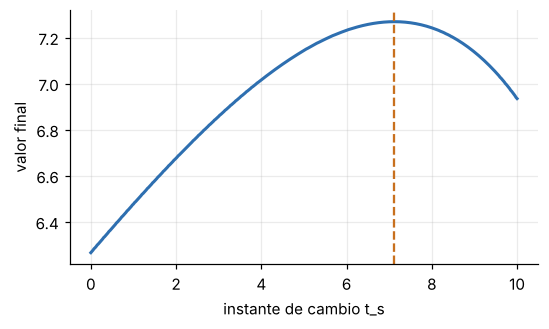

✔ el instante óptimo de cambio es ≈ 7,12


In [ ]:
# Fija los valores terminales b₁ y b₂, las tasas de reinversión g₁ y g₂ y el horizonte de la diap. 46.
b1, b2, g1, g2, Tf = 1.0, 0.8, 0.10, 0.16, 10.0
# Diap. 46. τ es el tiempo que queda tras la conmutación, definido por λ₁ = λ₂.
# Se resta τ al horizonte Tf para obtener t_s, medido desde el inicio.
tau = np.log(1 + g1*(b1 - b2)/(b1*(g2 - g1)))/g1; ts_formula = Tf - tau
# Define la función que evalúa un instante de cambio mediante una simulación hacia adelante.
def valor_final(ts, n_=2000):
    # Calcula el paso temporal e inicializa ambas capacidades en 1.
    h = Tf/n_; K1 = K2 = 1.0
    # Recorre los instantes de la simulación donde se decide a qué modelo asignar el fondo.
    for k in range(n_):
        # φ reparte el fondo Z = g₁K₁ + g₂K₂: antes de t_s todo va al modelo 2 y desde t_s va al modelo 1.
        phi = 1.0 if k*h >= ts else 0.0; Z = g1*K1 + g2*K2
        # Euler aplica las velocidades φZ y (1−φ)Z durante un paso de tamaño h.
        K1 += h*phi*Z; K2 += h*(1 - phi)*Z
    # Se evalúa el objetivo terminal, ponderando cada capacidad por su valor al cierre.
    return b1*K1 + b2*K2
# La rejilla prueba 401 instantes para comparar el mayor valor terminal simulado con la fórmula de Pontryagin.
grid = np.linspace(0, Tf, 401); vals = [valor_final(s_) for s_ in grid]
# Compara la predicción analítica con el instante de la rejilla de mayor valor simulado.
print(f"Fórmula: t_s = {ts_formula:.3f}   búsqueda directa: t_s = {grid[int(np.argmax(vals))]:.3f}")
# Grafica el objetivo según t_s y marca la conmutación analítica con una línea vertical.
plt.figure(figsize=(5.5, 3)); plt.plot(grid, vals, color=AZUL, lw=2); plt.axvline(ts_formula, color=NARANJA, ls="--")
# Rotula el instante de cambio y el valor obtenido al final del proyecto.
plt.xlabel("instante de cambio t_s"); plt.ylabel("valor final"); plt.show()
# Comprueba que el mejor instante en la rejilla queda a menos de 0.05 del calculado por fórmula.
assert abs(grid[int(np.argmax(vals))] - ts_formula) < 0.05
# Indica el instante de conmutación aproximado que se comprobó.
ok("el instante óptimo de cambio es ≈ 7,12")

## 3.4 El coestado es la retropropagación (diapositiva 48)
Sistema $x_{k+1}=x_k+\Delta t(-x_k^3+u_k)$. Calculamos $\partial J/\partial u_k$ con **una pasada hacia atrás** (coestado)
y lo comparamos con diferencias finitas (que necesitan $N$ simulaciones).

In [ ]:
# Fija el número de intervalos Nk, el paso h, el peso ρ del esfuerzo y el estado inicial x₀.
Nk, h, rho, x0 = 40, 0.05, 0.1, -0.5
# Define la función que obtiene los estados a partir de una secuencia de controles.
def simular(u):
    # Reserva un estado por nodo temporal y coloca x₀ en el primero.
    x_ = np.zeros(Nk + 1); x_[0] = x0
    # Diap. 26 y 48. La pasada hacia adelante aplica la transición F(x,u) = x + h(−x³+u) de Euler.
    for k in range(Nk): x_[k+1] = x_[k] + h*(-x_[k]**3 + u[k])
    # Devuelve todos los estados, del inicial al terminal, para evaluar los costes.
    return x_
# Define el coste total como función de la secuencia de controles.
def J_ctrl(u):
    # El coste por paso es h(xₖ² + ρuₖ²). El término terminal Φ = 10(x_N−1)² penaliza quedar lejos de 1.
    x_ = simular(u); return np.sum(h*(x_[:-1]**2 + rho*u**2)) + 10*(x_[-1] - 1)**2
# Define el cálculo del gradiente respecto de todos los controles mediante el coestado discreto.
def grad_adjunto(u):
    # La pasada hacia atrás empieza en λ_N = Φ′(x_N) = 20(x_N−1), como en la condición terminal de la diap. 42.
    x_ = simular(u); lam_ = 20*(x_[-1] - 1); g = np.zeros(Nk)
    # Recorre los controles desde el último intervalo hasta el inicial para propagar el coestado.
    for k in range(Nk - 1, -1, -1):
        # Con λ_{k+1} aún disponible, se suma la derivada directa del coste y la indirecta vía x_{k+1}.
        # Aquí ∂ℓₖ/∂uₖ = 2hρuₖ y ∂F/∂uₖ = h.
        g[k] = h*2*rho*u[k] + h*lam_                       # ∂H/∂u
        # La regla de la cadena agrega 2hxₖ y propaga λ_{k+1} con ∂F/∂xₖ = 1−3hxₖ² para obtener λₖ.
        lam_ = h*2*x_[k] + (1 - 3*h*x_[k]**2)*lam_          # λ_k = ∂ℓ/∂x + (∂f/∂x) λ_{k+1}
    # Devuelve un vector con una derivada del coste por cada componente del control.
    return g
# Genera una secuencia de prueba reproducible con media 0 y desviación estándar 0.5.
u0 = np.random.default_rng(1).normal(0, 0.5, Nk)
# La diferencia central perturba una componente uₖ a la vez. Cada componente requiere dos evaluaciones de J.
# La pasada adjunta calcula todas las componentes en el mismo recorrido hacia atrás.
g_fd = np.array([(J_ctrl(u0 + 1e-6*e) - J_ctrl(u0 - 1e-6*e))/2e-6 for e in np.eye(Nk)])
# Muestra la mayor diferencia absoluta entre las componentes de los dos gradientes.
print(f"Diferencia máxima adjunto vs diferencias finitas: {np.max(np.abs(grad_adjunto(u0) - g_fd)):.2e}")
# Comprueba que la discrepancia con las diferencias finitas es menor que 10⁻⁶.
assert np.max(np.abs(grad_adjunto(u0) - g_fd)) < 1e-6
# Señala que la recurrencia hacia atrás produjo el gradiente completo.
ok("el coestado da el gradiente exacto con una sola pasada hacia atrás")

Diferencia máxima adjunto vs diferencias finitas: 4.98e-09
✔ el coestado da el gradiente exacto con una sola pasada hacia atrás


**Opcional (PyTorch).** Colab trae PyTorch: el mismo gradiente sale de `autograd`, porque la retropropagación *es* el adjunto.

In [ ]:
# Intenta ejecutar la comparación opcional en un entorno que tenga PyTorch disponible.
try:
    # Importa PyTorch para construir el grafo de operaciones y calcular derivadas automáticamente.
    import torch
    # Diap. 48. requires_grad registra la dependencia del coste respecto de cada componente del control.
    ut = torch.tensor(u0, requires_grad=True, dtype=torch.float64); xx = torch.tensor(x0, dtype=torch.float64); JJ = 0
    # Recorre los intervalos en orden temporal para construir la misma simulación diferenciable.
    for k in range(Nk):
        # Se acumula el coste del estado actual antes de aplicar la transición de Euler al estado siguiente.
        JJ = JJ + h*(xx**2 + rho*ut[k]**2); xx = xx + h*(-xx**3 + ut[k])
    # backward propaga desde el coste total, incluido Φ, y deja en ut.grad los mismos ∂J/∂uₖ del adjunto.
    (JJ + 10*(xx - 1)**2).backward()
    # Compara coordenada a coordenada el gradiente de PyTorch y el calculado por la recurrencia adjunta.
    print(f"Diferencia adjunto vs torch.autograd: {np.max(np.abs(ut.grad.numpy() - grad_adjunto(u0))):.1e}")
# Maneja el caso en que la dependencia opcional no está instalada.
except ImportError:
    # Explica cómo continuar con el cuaderno si la importación falla.
    print("PyTorch no está disponible: puede omitir esta celda.")

Diferencia adjunto vs torch.autograd: 2.2e-16


---
# Bloque 4 · Programación dinámica
## 4.1 Ruta de menor latencia en microservicios (diapositiva 51)

In [25]:
# Guarda las latencias en milisegundos como pesos de aristas dirigidas (origen, destino), según la diap. 51.
aristas = {("gateway", "auth"): 4, ("gateway", "cache"): 2, ("auth", "catalogo"): 5, ("cache", "catalogo"): 8,
           # Añade las conexiones intermedias que pasan por búsqueda, catálogo y precios.
           ("cache", "busqueda"): 3, ("busqueda", "catalogo"): 2, ("catalogo", "precios"): 3,
           # Completa las conexiones alternativas y las que terminan en la base de datos.
           ("busqueda", "precios"): 7, ("precios", "db"): 1, ("catalogo", "db"): 6}
# Reúne los extremos de las aristas y ordena los nodos para obtener una lista sin duplicados.
nodos = sorted({a for e in aristas for a in e})
# Define el cálculo de la latencia mínima desde cada nodo hasta el destino.
def bellman_grafo(aristas, destino="db"):
    # Diap. 50–51. V(s) estima la menor latencia hasta el destino, cuyo coste restante es cero.
    # Los demás nodos empiezan en infinito hasta descubrir una ruta.
    V = {s: (0.0 if s == destino else np.inf) for s in nodos}; suc = {}
    # Conserva una copia de V y suc al inicio y después de cada iteración para comparar su evolución.
    historial = [(0, V.copy(), suc.copy())]
    # Repite la relajación |nodos|−1 veces, la longitud máxima en aristas de una ruta simple.
    for _ in range(len(nodos) - 1):                       # Bellman–Ford
        # Recorre cada arista s→s₂ y toma su coste inmediato c para evaluar una posible mejora.
        for (s, s2), c in aristas.items():
            # La ecuación de Bellman compara la mejor latencia conocida con c(s,s₂) + V(s₂).
            # Si mejora, se guarda s₂ como siguiente nodo de la ruta.
            if c + V[s2] < V[s]:
                # Actualiza el menor coste conocido y registra el siguiente nodo que permite alcanzarlo.
                V[s], suc[s] = c + V[s2], s2
        # Guarda el estado alcanzado al terminar esta pasada completa sobre todas las aristas.
        historial.append((len(historial), V.copy(), suc.copy()))
    # Devuelve las latencias mínimas, los sucesores y su evolución para reconstruir y analizar las rutas.
    return V, suc, historial
# Calcula los costes mínimos y sucesores de la red original.
V, suc, historial = bellman_grafo(aristas)
# Inicializa la ruta y el nodo actual en gateway, el punto de entrada a la red.
ruta, s = ["gateway"], "gateway"
# La ruta se reconstruye siguiendo el sucesor elegido en cada estado hasta llegar al destino.
while s != "db":
    # Avanza al sucesor óptimo del nodo actual y agrégalo a la ruta.
    s = suc[s]; ruta.append(s)
# Muestra una fila por nodo y una columna por iteración, incluido el estado inicial.
orden_nodos = ["db", "precios", "catalogo", "busqueda", "cache", "auth", "gateway"]
filas = [["Nodo", *(f"Iter. {i}" for i, _, _ in historial)]]
for nodo in orden_nodos:
    fila = [nodo]
    for _, V_iter, suc_iter in historial:
        valor = "∞" if np.isinf(V_iter[nodo]) else f"{V_iter[nodo]:g}"
        fila.append(f"{valor}/{suc_iter.get(nodo, '—')}")
    filas.append(fila)
anchos = [max(map(len, columna)) for columna in zip(*filas)]
print("V (ms)/suc · Iter. 0 = inicio · — = sin sucesor")
for fila in filas:
    print(" | ".join(f"{dato:<{ancho}}" for dato, ancho in zip(fila, anchos)).rstrip())
# Presenta la secuencia de microservicios y su latencia total.
print("Ruta óptima:", " → ".join(ruta), f"({V['gateway']:.0f} ms)")
# Verifica que el menor coste desde gateway es 11 ms.
assert V["gateway"] == 11
# Confirma la latencia mínima de la red de ejemplo.
ok("latencia mínima 11 ms")

V (ms)/suc · Iter. 0 = inicio · — = sin sucesor
Nodo     | Iter. 0 | Iter. 1 | Iter. 2     | Iter. 3     | Iter. 4    | Iter. 5    | Iter. 6
db       | 0/—     | 0/—     | 0/—         | 0/—         | 0/—        | 0/—        | 0/—
precios  | ∞/—     | 1/db    | 1/db        | 1/db        | 1/db       | 1/db       | 1/db
catalogo | ∞/—     | 6/db    | 4/precios   | 4/precios   | 4/precios  | 4/precios  | 4/precios
busqueda | ∞/—     | ∞/—     | 8/catalogo  | 6/catalogo  | 6/catalogo | 6/catalogo | 6/catalogo
cache    | ∞/—     | ∞/—     | 14/catalogo | 11/busqueda | 9/busqueda | 9/busqueda | 9/busqueda
auth     | ∞/—     | ∞/—     | 11/catalogo | 9/catalogo  | 9/catalogo | 9/catalogo | 9/catalogo
gateway  | ∞/—     | ∞/—     | ∞/—         | 15/auth     | 13/auth    | 11/cache   | 11/cache
Ruta óptima: gateway → cache → busqueda → catalogo → precios → db (11 ms)
✔ latencia mínima 11 ms


## 4.2 Dos decisiones resueltas hacia atrás (diapositiva 53)

In [28]:
# Fija las tres acciones discretas permitidas en ambas etapas (diap. 53).
U = [-1, 0, 1]
# Diap. 52–53. La última etapa solo cobra el coste terminal x₂².
V2 = lambda x_: x_**2
# Cada acción paga u₁² y deja el estado x₂ = x₁+u₁. Bellman elige el menor coste inmediato más el restante.
V1 = lambda x_: min(u**2 + V2(x_ + u) for u in U)
# Se aplica la misma recurrencia desde x₀ = 1, usando el valor de la etapa 1 ya calculado.
V0 = min(u**2 + V1(1 + u) for u in U)
# Enumerar pares de acciones usa x₂ = 1+a+b y permite comprobar el mínimo y los empates.
todas = {(a, b): a**2 + b**2 + (1 + a + b)**2 for a, b in itertools.product(U, U)}
# Compara horizontalmente el coste inmediato más el restante para cada acción.
print("Coste por acción (u² + valor de la etapa siguiente)")
encabezados = ["Etapa", "Estado", *(f"u={u}" for u in U), "V mínimo"]
print(" | ".join(f"{titulo:>8}" for titulo in encabezados))
print("-+-".join("-" * 8 for _ in encabezados))
for etapa, estados, valor_siguiente in [(1, [1 + u for u in U], V2), (0, [1], V1)]:
    for estado in estados:
        costes = [u**2 + valor_siguiente(estado + u) for u in U]
        fila = [etapa, estado, *costes, min(costes)]
        print(" | ".join(f"{valor:>8}" for valor in fila))
# Selecciona todos los pares de acciones cuyo coste total coincide con el mínimo enumerado.
print("Políticas óptimas por enumeración:", [k for k, v_ in todas.items() if v_ == min(todas.values())])
# Comprueba que la recurrencia de Bellman da un coste inicial de 1.
assert V0 == 1
# Informa del coste mínimo y de los tres pares de acciones que lo alcanzan.
ok("coste mínimo 1 con tres políticas óptimas")

Coste por acción (u² + valor de la etapa siguiente)
   Etapa |   Estado |     u=-1 |      u=0 |      u=1 | V mínimo
---------+----------+----------+----------+----------+---------
       1 |        0 |        2 |        0 |        2 |        0
       1 |        1 |        1 |        1 |        5 |        1
       1 |        2 |        2 |        4 |       10 |        2
       0 |        1 |        1 |        1 |        3 |        1
Políticas óptimas por enumeración: [(-1, 0), (0, -1), (0, 0)]
✔ coste mínimo 1 con tres políticas óptimas


## 4.3 Reservar GPU sin saber la demanda (diapositiva 54)

In [35]:
# Desglosa el coste esperado de reservar q GPU antes de observar la demanda.
def componentes_reserva(q):
    # Diap. 54. q cuesta una unidad por GPU reservada. Se añade la esperanza del coste por faltantes
    # 3·max(w−q,0) y ociosidad 0.5·max(q−w,0), ponderados por las probabilidades de la diap. 17.
    faltantes = np.sum(pw * 3 * np.maximum(w - q, 0))
    ociosidad = np.sum(pw * 0.5 * np.maximum(q - w, 0))
    return q, faltantes, ociosidad
def coste_reserva(q):
    return sum(componentes_reserva(q))
# Se evalúa C(q) para cada cantidad entera candidata. Por encima de la demanda máxima, C(q) crece.
cantidades = range(5)
componentes = [componentes_reserva(q) for q in cantidades]
tabla = {q: sum(partes) for q, partes in zip(cantidades, componentes)}
q_optima = min(tabla, key=tabla.get)
acumuladas = [np.sum(pw[w <= q]) for q in cantidades]
# Coloca las cantidades de GPU en columnas para comparar todos los costes.
print(f"{'GPU reservadas (q)':<20} | " + " | ".join(f"{q:>6}" for q in cantidades))
print("-+-".join(["-" * 20] + ["-" * 6] * len(cantidades)))
filas = list(zip(["Reserva", "Faltantes (esp.)", "Ociosidad (esp.)"], zip(*componentes)))
filas += [("Coste total C(q)", tabla.values()), ("P(w ≤ q)", acumuladas)]
for etiqueta, valores in filas:
    decimales = 3 if etiqueta == "P(w ≤ q)" else 2
    print(f"{etiqueta:<20} | " + " | ".join(f"{valor:>6.{decimales}f}" for valor in valores))
# El coste marginal C(q+1)−C(q) es 1−3+(3+0.5)P(w≤q).
# El primer q cuyo marginal es no negativo cumple la regla del fractil.
umbral = (3 - 1) / (3 + 0.5)
q_fractil = next(q for q, prob in zip(cantidades, acumuladas) if prob >= umbral)
print(f"q* = {q_optima} GPU | Regla del fractil: primer q con P(w ≤ q) ≥ {umbral:.3f} → q = {q_fractil}")
# Verifica que la reserva elegida es 2 y que su coste total esperado es 2.85.
assert q_optima == q_fractil == 2 and abs(tabla[2] - 2.85) < 1e-9
# Resume la decisión óptima y el coste que resulta de tomarla.
ok("reservar 2 GPU con coste esperado 2,85")

GPU reservadas (q)   |      0 |      1 |      2 |      3 |      4
---------------------+--------+--------+--------+--------+-------
Reserva              |   0.00 |   1.00 |   2.00 |   3.00 |   4.00
Faltantes (esp.)     |   5.10 |   2.40 |   0.60 |   0.00 |   0.00
Ociosidad (esp.)     |   0.00 |   0.05 |   0.25 |   0.65 |   1.15
Coste total C(q)     |   5.10 |   3.45 |   2.85 |   3.65 |   5.15
P(w ≤ q)             |  0.100 |  0.400 |  0.800 |  1.000 |  1.000
q* = 2 GPU | Regla del fractil: primer q con P(w ≤ q) ≥ 0.571 → q = 2
✔ reservar 2 GPU con coste esperado 2,85


**Pruébelo.** Suba el coste de faltante de 3 a 6. ¿Cuántas GPU conviene reservar ahora? ¿Coincide con la regla del fractil?

## 4.4 La maldición de la dimensión (diapositiva 55)

In [ ]:
# Compara sistemas con distintas cantidades d de variables de estado (diap. 55).
for d in [1, 2, 3, 4, 6]:
    # Diap. 55. Con 100 niveles para cada una de d variables, el producto cartesiano tiene 100ᵈ estados.
    print(f"{d} variables × 100 niveles = {100**d:>16,} estados")

1 variables × 100 niveles =              100 estados
2 variables × 100 niveles =           10,000 estados
3 variables × 100 niveles =        1,000,000 estados
4 variables × 100 niveles =      100,000,000 estados
6 variables × 100 niveles = 1,000,000,000,000 estados


## 4.5 Puente Pontryagin–Bellman: λ = ∂V/∂x (diapositiva 57)
Para el problema de energía mínima, $V(t,x)=\frac{(1-x)^2}{2(1-t)}$. Sobre la trayectoria óptima $x=t$, $\partial V/\partial x=-1=\lambda$.

Valores sobre la trayectoria óptima x*(t) = t
t              |  0.000 |  0.250 |  0.500 |  0.750 |  0.990
x*(t)          |  0.000 |  0.250 |  0.500 |  0.750 |  0.990
V(t, x*)       |  0.500 |  0.375 |  0.250 |  0.125 |  0.005
∂V/∂x          | -1.000 | -1.000 | -1.000 | -1.000 | -1.000
u* = −∂V/∂x    |  1.000 |  1.000 |  1.000 |  1.000 |  1.000
Residuo de la ecuación HJB (debe ser 0): 0
✔ V satisface la HJB y su gradiente es el coestado


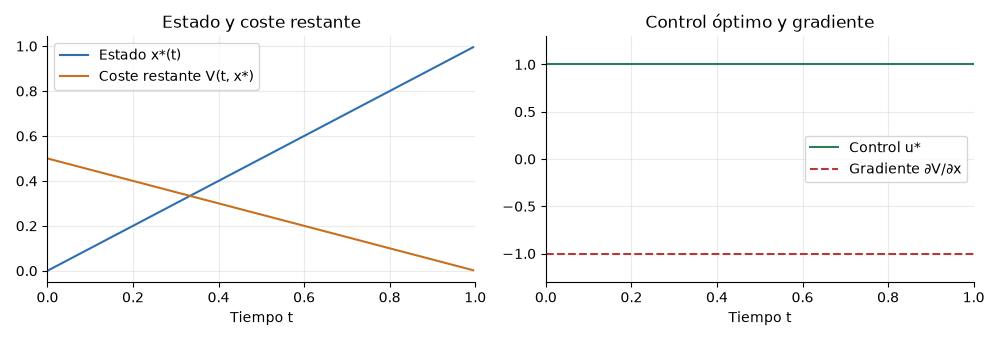

In [39]:
# Declara el tiempo t y el estado x como variables simbólicas independientes.
tt_, xx_ = sp.symbols("t x")
# Diap. 57. Para t < 1 quedan tiempo 1−t y distancia 1−x. El control óptimo constante en el tiempo restante
# es (1−x)/(1−t), así que su energía mínima es V(t,x) = (1−x)²/[2(1−t)].
Vtx = (1 - xx_)**2/(2*(1 - tt_))
# Evalúa el valor, el gradiente y el control sobre la trayectoria óptima x*(t) = t.
Vx = sp.diff(Vtx, xx_)
valor_trayectoria = sp.simplify(Vtx.subs(xx_, tt_))
gradiente_trayectoria = sp.simplify(Vx.subs(xx_, tt_))
# Incluye una muestra cerca del tiempo terminal, donde la fórmula original exige t < 1.
tiempos = [sp.Rational(p, 100) for p in (0, 25, 50, 75, 99)]
filas = [("t", tt_), ("x*(t)", tt_), ("V(t, x*)", valor_trayectoria),
         ("∂V/∂x", gradiente_trayectoria), ("u* = −∂V/∂x", -gradiente_trayectoria)]
print("Valores sobre la trayectoria óptima x*(t) = t")
for etiqueta, expresion in filas:
    valores = [float(expresion.subs(tt_, tiempo)) for tiempo in tiempos]
    print(f"{etiqueta:<14} | " + " | ".join(f"{valor:>6.3f}" for valor in valores))
# HJB: -V_t = min_u { u²/2 + V_x u }  con u* = -V_x
# Diap. 56. Al sustituir u* = −Vₓ en el Hamiltoniano, su mínimo vale −Vₓ²/2.
# El código resta ese valor a −Vₜ para comprobar la ecuación de Hamilton–Jacobi–Bellman.
hjb = sp.simplify(-sp.diff(Vtx, tt_) + Vx**2/2)
# Muestra la diferencia simplificada entre los dos lados de la ecuación HJB.
print("Residuo de la ecuación HJB (debe ser 0):", hjb)
# Verifica que el residuo simbólico se anula.
assert hjb == 0
# Resume la verificación de HJB y la relación entre el gradiente de valor y el coestado.
ok("V satisface la HJB y su gradiente es el coestado")

# Dibuja las cuatro variables sobre la trayectoria óptima, en el dominio t < 1.
t_graf = np.linspace(0, 1, 200, endpoint=False)
fig_hjb, (ax_trayectoria, ax_control) = plt.subplots(1, 2, figsize=(10, 3.4), sharex=True)
valor_graf = sp.lambdify(tt_, valor_trayectoria, modules="numpy")
ax_trayectoria.plot(t_graf, t_graf, color=AZUL, label="Estado x*(t)")
ax_trayectoria.plot(t_graf, valor_graf(t_graf), color=NARANJA, label="Coste restante V(t, x*)")
ax_trayectoria.set_title("Estado y coste restante")
ax_control.axhline(float(-gradiente_trayectoria), color=VERDE, label="Control u*")
ax_control.axhline(float(gradiente_trayectoria), color=ROJO, linestyle="--", label="Gradiente ∂V/∂x")
ax_control.set_title("Control óptimo y gradiente")
ax_control.set_ylim(-1.3, 1.3)
for eje_hjb in (ax_trayectoria, ax_control):
    eje_hjb.set(xlabel="Tiempo t", xlim=(0, 1))
    eje_hjb.legend()
fig_hjb.tight_layout()
plt.show()

## 4.6 LQR: Riccati continuo y discreto (diapositivas 58–59)

Continuo (a = 0,2, b = q = r = 1): P = 1.2198; lazo cerrado ẋ = -1.0198 x
a, b, q, r = 1.05, -0.8, 1.0, 0.5: Discreto: P = 1.5758, u = 0.8775·D, factor en lazo cerrado = 0.348

Convergencia de Riccati (iteración 0 = valor inicial)
Iteración         |        0        1        2        3        4        5        6        7
P                 |   1.0000   1.4836   1.5642   1.5744   1.5757   1.5758   1.5758   1.5758
Iteración         |        8        9       10       11       12       13       14       15
P                 |   1.5758   1.5758   1.5758   1.5758   1.5758   1.5758   1.5758   1.5758
Iteración         |       16       17       18       19       20       21       22       23
P                 |   1.5758   1.5758   1.5758   1.5758   1.5758   1.5758   1.5758   1.5758
Iteración         |       24       25       26       27       28       29       30
P                 |   1.5758   1.5758   1.5758   1.5758   1.5758   1.5758   1.5758

Deuda técnica por sprint (horas)
Sprint           

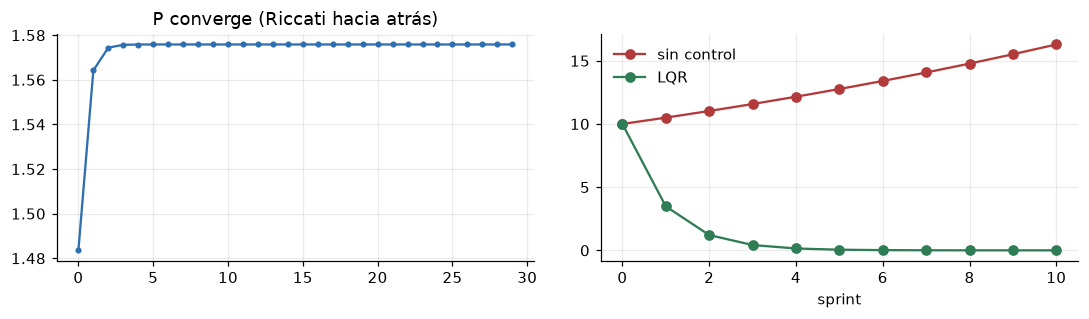

✔ P = 1,2198 (continuo) y P = 1,576, u = 0,878 D (discreto)


In [40]:
# Declara positivo el coeficiente P de la función de valor cuadrática V(x) = Px².
P = sp.symbols("P", positive=True)
# Diap. 58. Con V(x) = Px², minimizar la HJB da u* = −bPx/r y la ecuación q + 2aP − b²P²/r = 0.
# Con a = 0.2 y b = q = r = 1 se elige la raíz positiva para que V sea positiva fuera del origen.
Pc = sp.solve(1 + 2*sp.Rational(1, 5)*P - P**2, P)[0]
# Muestra la raíz de Riccati y la tasa a − b²P/r que resulta al aplicar el control continuo.
print(f"Continuo (a = 0,2, b = q = r = 1): P = {float(Pc):.4f}; lazo cerrado ẋ = {0.2 - float(Pc):.4f} x")
# Diap. 59. En discreto, Dₖ₊₁ = aDₖ+buₖ y el coste es qDₖ²+ruₖ². Aquí b < 0 porque refactorizar reduce deuda.
a, b, q, r = 1.05, -0.8, 1.0, 0.5
# Inicializa en 1 el coeficiente de valor y crea un historial para observar su convergencia.
P_inicial = 1.0
Pk, hist = P_inicial, []
# Aplica 30 veces la recurrencia hacia atrás para aproximar el coeficiente de horizonte infinito.
for _ in range(30):
    # Con Pk como coeficiente del valor futuro, minimizar qD²+ru²+Pk(aD+bu)² da u = −KD.
    # Sustituir ese control da el nuevo coeficiente de Riccati. Las iteraciones aproximan el punto fijo.
    K = b*Pk*a/(r + b*Pk*b); Pk = q + a*Pk*a - a*Pk*b*K; hist.append(Pk)
# Muestra el coeficiente de valor, la acción proporcional u = −KD y el factor de lazo cerrado.
print(f"a, b, q, r = 1.05, -0.8, 1.0, 0.5: Discreto: P = {Pk:.4f}, u = {-K:.4f}·D, factor en lazo cerrado = {a - b*K:.3f}")
# Inicializa con 10 horas las dos simulaciones para comparar las políticas en igualdad de condiciones.
D_lqr = [10.0]; D_nada = [10.0]
# Simula 10 sprints con y sin la política LQR.
for _ in range(10):
    # Con u = −KD, el factor por sprint es a−bK. Sin control, el factor de la misma dinámica es a.
    D_lqr.append((a - b*K)*D_lqr[-1]); D_nada.append(a*D_nada[-1])
# Imprime el historial completo en bloques horizontales de hasta ocho columnas.
def imprimir_evolucion(eje, series):
    cantidad = len(series[0][1])
    for inicio in range(0, cantidad, 8):
        indices = range(inicio, min(inicio + 8, cantidad))
        print(f"{eje:<17} | " + " ".join(f"{i:>8}" for i in indices))
        for etiqueta, valores in series:
            print(f"{etiqueta:<17} | " + " ".join(f"{valores[i]:8.4f}" for i in indices))

print("\nConvergencia de Riccati (iteración 0 = valor inicial)")
imprimir_evolucion("Iteración", [("P", [P_inicial, *hist])])
print("\nDeuda técnica por sprint (horas)")
imprimir_evolucion("Sprint", [("Con LQR", D_lqr), ("Sin control", D_nada)])
# Crea dos paneles, uno para Riccati y otro para la evolución de la deuda.
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
# Dibuja el valor de P después de cada iteración de la recurrencia.
ax[0].plot(hist, "o-", color=AZUL, ms=3); ax[0].set_title("P converge (Riccati hacia atrás)")
# Contrasta los historiales de deuda con u = 0 y con la realimentación óptima.
ax[1].plot(D_nada, "o-", color=ROJO, label="sin control"); ax[1].plot(D_lqr, "o-", color=VERDE, label="LQR")
# Rotula el eje de sprints, coloca la leyenda y ajusta el espacio entre paneles.
ax[1].set_xlabel("sprint"); ax[1].legend(frameon=False); plt.tight_layout(); plt.show()
# Comprueba que los coeficientes continuo y discreto se acercan a los valores de las diapositivas.
assert abs(float(Pc) - 1.2198) < 1e-4 and abs(Pk - 1.5758) < 1e-3
# Resume los coeficientes de valor y la política discreta obtenida.
ok("P = 1,2198 (continuo) y P = 1,576, u = 0,878 D (discreto)")

---
# Bloque 5 · Ejercicios
Complete cada `TODO` y ejecute la celda: si el `assert` no falla, la respuesta es correcta.
Las soluciones están al final del cuaderno: intente primero sin mirarlas.

In [ ]:
# Ejercicio 1: resuelva ẋ = −2x, x(0) = 5, y calcule x(1).
# Diap. 14. Usa la solución exponencial del modelo ẋ = ax con su condición inicial.
x1 = None  # TODO: escriba el valor numérico de x(1)
# Exige que se ingrese un valor y lo compara con la solución exponencial dentro de la tolerancia.
assert x1 is not None and abs(x1 - 5*np.exp(-2)) < 1e-3, "Pista: x(t) = x0·e^{at}"
# Confirma que el valor ingresado superó la comprobación del ejercicio 1.
ok("Ejercicio 1")

In [ ]:
# Ejercicio 2: paso máximo de Euler estable para ẋ = −4x.
# Diap. 26. Busca el umbral del paso a partir del módulo del factor de Euler. La desigualdad es estricta.
dt_max = None  # TODO
# Comprueba que se calculó el umbral superior de Δt a partir del criterio de estabilidad.
assert dt_max is not None and abs(dt_max - 0.5) < 1e-9, "Pista: |1 − kΔt| < 1"
# Confirma que el umbral ingresado pasó la comprobación del ejercicio 2.
ok("Ejercicio 2")

In [ ]:
# Ejercicio 3: equilibrio de D_{k+1} = 0,8 D_k + 6.
# Diap. 25 y 27. En un punto fijo discreto, la deuda del sprint siguiente es igual a la actual.
D_eq = None  # TODO
# Compara el valor ingresado con el punto fijo de la recurrencia de deuda.
assert D_eq is not None and abs(D_eq - 30) < 1e-9, "Pista: D* = 0,8 D* + 6"
# Confirma que el equilibrio ingresado superó la comprobación del ejercicio 3.
ok("Ejercicio 3")

In [ ]:
# Ejercicio 4: Euler–Lagrange para L = ẋ² + 4x, x(0) = 0, x(1) = 0. Escriba x*(t) como expresión de sympy.
# Diap. 34–35. Trata x y ẋ como variables separadas al derivar L y usa los dos extremos para fijar las constantes.
x4 = None  # TODO (use la variable simbólica t)
# Simplifica simbólicamente la diferencia entre la trayectoria ingresada y la esperada.
assert x4 is not None and sp.simplify(x4 - (t**2 - t)) == 0, "Pista: resuelva ẍ = 2"
# Confirma que la trayectoria ingresada coincide con la del ejercicio 4.
ok("Ejercicio 4")

In [ ]:
# Ejercicio 5: mín ∫0^2 ½u² dt, ẋ = u, x(0) = 0, x(2) = 4. Dé u* (constante) y J*.
# Diap. 44. Integra ẋ = u para imponer la distancia final y usa el control constante en la integral de energía.
u5, J5 = None, None  # TODO
# Comprueba juntos el control constante y el coste acumulado que produce.
assert u5 == 2 and J5 == 4, "Pista: con λ constante, u es constante"
# Confirma que el control y su coste superaron la comprobación del ejercicio 5.
ok("Ejercicio 5")

In [ ]:
# Ejercicio 6: en la red de microservicios, cambie cache→búsqueda a 6 ms y recalcule la latencia mínima.
# Diap. 51. Al cambiar una latencia se vuelven a comparar los costes inmediatos más los costes restantes.
aristas6 = dict(aristas)
# TODO: modifique aristas6 y use bellman_grafo
# Deja un marcador para guardar la latencia mínima desde gateway con la arista modificada.
V6 = None
# Contrasta la latencia calculada con el valor esperado para la red modificada.
assert V6 == 13, "Pista: aristas6[('cache','busqueda')] = 6"
# Confirma que se calculó la latencia mínima del ejercicio 6.
ok("Ejercicio 6")

In [ ]:
# Ejercicio 7: LQR escalar a = 0, b = 1, q = 4, r = 1. Calcule P y la ganancia K (u = −K x).
# Diap. 58. Para V(x) = Px² se busca la raíz positiva de Riccati y se calcula la ganancia a partir de P.
P7, K7 = None, None  # TODO
# Comprueba el coeficiente positivo de Riccati y la ganancia de la ley de control.
assert P7 == 2 and K7 == 2, "Pista: q + 2aP − b²P²/r = 0"
# Confirma que ambos valores superaron la comprobación del ejercicio 7.
ok("Ejercicio 7")

---
# Soluciones de los ejercicios

In [ ]:
# Ej. 1 (diap. 65). Evalúa x(t) = x₀exp(at) con x₀ = 5, a = −2 y t = 1.
x1 = 5*np.exp(-2)                                       # 1
# Ej. 2. El valor 2/4 es el umbral de estabilidad de Euler para el factor 1−4Δt. El umbral queda excluido.
dt_max = 2/4                                            # 2
# Ej. 3. Despejar D* de D* = 0.8D* + 6 da el equilibrio al que converge la dinámica.
D_eq = 6/(1 - 0.8)                                      # 3
# Ej. 4. Para L = ẋ² + 4x, Euler–Lagrange da 2ẍ = 4. Los extremos fijos determinan las constantes.
x4 = resolver_EL(X(t).diff(t)**2 + 4*X(t), {X(0): 0, X(1): 0})[1].rhs   # 4
# Ej. 5. Pontryagin da u constante. Se divide el desplazamiento entre 2 y se integra ½u² a lo largo del horizonte de duración 2.
u5, J5 = 2, 4                                           # 5: u = 4/2, J = ∫0^2 ½·4 dt
# Copia la red antes de cambiar la latencia de caché a búsqueda para conservar el caso original.
aristas6 = dict(aristas); aristas6[("cache", "busqueda")] = 6
# Ej. 6. Bellman vuelve a calcular la menor latencia de gateway hasta db con el nuevo peso de la arista.
V6 = bellman_grafo(aristas6)[0]["gateway"]              # 6
# Ej. 7. Con a = 0 y b = r = 1, Riccati da 4 − P² = 0 y la ganancia K = bP/r coincide con la raíz positiva.
P7 = int(sp.solve(4 - P**2, P)[0]); K7 = P7             # 7: K = bP/r
# Muestra las cuatro primeras soluciones y expande x*(t) para presentarla como polinomio.
print(f"1) x(1) = {x1:.4f}   2) Δt < {dt_max}   3) D* = {D_eq:.0f}   4) x* = {sp.expand(x4)}")
# Muestra el control y su coste, la nueva latencia y los parámetros de Riccati.
print(f"5) u* = {u5}, J* = {J5}   6) latencia = {V6:.0f} ms   7) P = {P7}, K = {K7}")

1) x(1) = 0.6767   2) Δt < 0.5   3) D* = 30   4) x* = t**2 - t
5) u* = 2, J* = 4   6) latencia = 13 ms   7) P = 2, K = 2
